# Which manhole did the pollution come from? Tracer tests on the real Bellinge sewer network, Denmark

**KAI Water & Energy case studies** · [Interactive version on the KAI platform](https://hydro-saas.charkaks0.workers.dev/demo/reference/bellinge) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free)

When a treatment plant's inlet suddenly shows a spike of metals or oil, every factory upstream says *it was
not us*. Finding the source means reading a few sensors in the sewer and working backwards through the
network. This notebook shows why that is hard, and what makes it work, on a real network:

1. load the open SWMM model of the **Bellinge** sewer system in Odense, Denmark (about 1,000 manholes);
2. run it in dry weather with the official **EPA SWMM 5** engine, and check the water and mass balance;
3. release tracer at three manholes and watch what sensors at the plant inlet and inside the network see;
4. see why manholes on the same sewer line look alike at the inlet, and how a few well-placed sensors fix that;
5. read the results of KAI's blind test: 53 hidden releases, found from sensor data alone.

Runtime: about two minutes.

## The data

* **Network model:** the SWMM model of the Bellinge and Brændekilde combined sewer system (manholes, pipes,
  pumps, basins, overflows, control rules) with the utility's dry-weather inflows, from the open
  **Bellinge data set**: Nedergaard Pedersen, A., Wied Pedersen, J., Vigueras-Rodriguez, A., Brink-Kjær, A.,
  Borup, M. and Steen Mikkelsen, P. (2021). *The Bellinge data set: open data and models for community-wide urban
  drainage systems research.* Earth System Science Data 13, 4779–4798.
  [doi:10.5194/essd-13-4779-2021](https://doi.org/10.5194/essd-13-4779-2021). Licence **CC BY 4.0**.
* File `BellingeSWMM_v021_nopervious.inp` as distributed by the
  [eWaterCycle/ewatercycle-swmm](https://github.com/eWaterCycle/ewatercycle-swmm) repository (BSD-2-Clause; see `../LICENSES/`),
  commit `9dcc535`, vendored unchanged in `data/` (SHA-256 `1ac98b81…c472c`).
* **Not used:** the Bellinge rain-gauge records (licensed for teaching and research only). This case runs in
  dry weather, when an industrial spill is least diluted.
* **Simulated, and labelled as such:** the tracer releases. The network has no public pollutant records, so
  every release is a virtual tracer test of known mass, place and time.

In [1]:
import hashlib
import json
import os
import re
import tempfile
import warnings
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from swmm.toolkit import output, shared_enum, solver

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

INP = Path("data/BellingeSWMM_v021_nopervious.inp")
assert hashlib.sha256(INP.read_bytes()).hexdigest() == "1ac98b81fbce2a42898423e2cf120ed46d36910637f73ad27c2a1004973c472c", "model file changed"
TEXT = INP.read_text()
print("EPA SWMM", solver.swmm_version_info() if hasattr(solver, "swmm_version_info") else "5.x")

EPA SWMM 5.2.4


## Step 1 · Read the network

995 manholes, 16 basins, 9 outfalls, 6 pumps, 1044 links; dry-weather inflow enters at 449 manholes


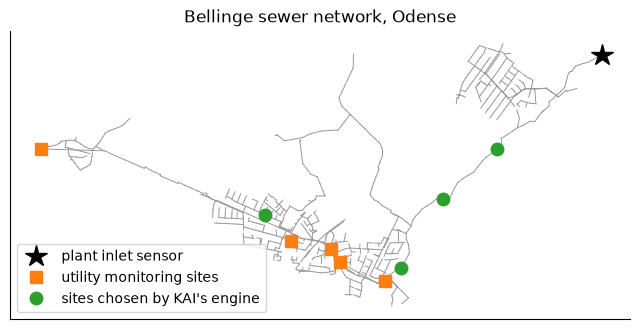

In [2]:
def sections(text):
    out, cur = {}, None
    for raw in text.splitlines():
        line = raw.strip()
        m = re.match(r"^\[([A-Za-z_]+)\]", line)
        if m:
            cur = m.group(1).upper(); out.setdefault(cur, []); continue
        if cur and line and not line.startswith(";"):
            out[cur].append(line.split())
    return out

S = sections(TEXT)
coords = {p[0]: (float(p[1]), float(p[2])) for p in S["COORDINATES"]}
links = [(p[0], p[1], p[2]) for sec in ("CONDUITS", "PUMPS", "ORIFICES", "WEIRS", "OUTLETS") for p in S.get(sec, [])]
dwf = {}
for p in S["DWF"]:
    if p[1].upper() == "FLOW":
        dwf[p[0]] = dwf.get(p[0], 0) + float(p[2])
print(f"{len(S['JUNCTIONS'])} manholes, {len(S['STORAGE'])} basins, {len(S['OUTFALLS'])} outfalls, {len(S['PUMPS'])} pumps, "
      f"{len(links)} links; dry-weather inflow enters at {len(dwf)} manholes")

OUTLET = "F74F360"                                           # interceptor towards the treatment plant
UTILITY = ["G71F05R", "G71F68Y", "G72F040", "G73F010", "G80F13P"]   # the utility's real monitoring sites
CHOSEN = ["G71F030", "G63F080", "G74F220", "G65F040"]       # four sites chosen by the KAI engine (see below)

fig, ax = plt.subplots(figsize=(8, 8))
for _, a, b in links:
    if a in coords and b in coords:
        ax.plot(*zip(coords[a], coords[b]), color="0.6", lw=0.7)
ax.plot(*coords[OUTLET], "k*", ms=16, label="plant inlet sensor")
ax.plot(*zip(*[coords[n] for n in UTILITY]), "s", color="tab:orange", ms=8, label="utility monitoring sites")
ax.plot(*zip(*[coords[n] for n in CHOSEN]), "o", color="tab:green", ms=9, label="sites chosen by KAI's engine")
ax.set(aspect="equal", xticks=[], yticks=[], title="Bellinge sewer network, Odense")
ax.legend(loc="lower left");

## Step 2 · Prepare a run: dry weather, tracers, the nodes we read

Three changes to the model text, nothing else:

* every rain gauge reads a series of zeros (dry weather);
* one **conservative tracer** per release, entered as a mass inflow at the release manhole;
* results are written every 5 minutes for the sensor nodes only.

One detail worth knowing: SWMM keeps mass flow internally in (mg/L)·(ft³/s), so a `MASS` inflow's scale factor
must include 28.317 litres per cubic foot to deliver the intended kilograms, whatever the flow units. We check
the mass balance below rather than trust it.

In [3]:
LITRES_PER_FT3 = 28.316847
MASS_FACTOR = 1e6 / 3600.0 * LITRES_PER_FT3      # kg/h  →  SWMM mass-inflow units


def fmt(d):
    return d.strftime("%m/%d/%Y"), d.strftime("%H:%M:%S")


def prepare(start, end, releases, nodes, step_min=5):
    """releases: [(tracer name, manhole, release start, minutes, kg/h)]"""
    out, sec = [], None
    drop = {"POLLUTANTS", "INFLOWS", "REPORT", "LOADINGS", "BUILDUP", "WASHOFF", "LANDUSES", "COVERAGES"}
    sd, st = fmt(start); ed, et = fmt(end)
    opts = {"START_DATE": sd, "START_TIME": st, "REPORT_START_DATE": sd, "REPORT_START_TIME": st, "END_DATE": ed, "END_TIME": et,
            "REPORT_STEP": f"00:{step_min:02d}:00", "SWEEP_START": "01/01", "SWEEP_END": "12/31", "THREADS": "1"}
    for raw in TEXT.splitlines():
        m = re.match(r"^\s*\[([A-Za-z_]+)\]", raw)
        if m:
            sec = m.group(1).upper()
            if sec not in drop:
                out.append(raw)
            continue
        if sec in drop:
            continue
        p = raw.split()
        if sec == "OPTIONS" and p and p[0].upper() in opts:
            out.append(f"{p[0].upper():<20} {opts[p[0].upper()]}"); continue
        if sec == "RAINGAGES" and p and not raw.strip().startswith(";"):
            out.append(f"{p[0]:<16} INTENSITY 00:05 1.0 TIMESERIES dry"); continue
        out.append(raw)
    ts = ["[TIMESERIES]", f"dry {sd} {st[:5]} 0", f"dry {ed} {et[:5]} 0"]
    pol, inf = ["[POLLUTANTS]"], ["[INFLOWS]"]
    for name, node, t0, minutes, kg_h in releases:
        pol.append(f"{name} MG/L 0 0 0 0 NO * 0 0 0")
        t1 = t0 + timedelta(minutes=minutes)
        for d, v in ((t0 - timedelta(minutes=1), 0), (t0, kg_h), (t1, kg_h), (t1 + timedelta(minutes=1), 0)):
            a, b = fmt(d); ts.append(f"s_{name} {a} {b[:5]} {v}")
        inf.append(f"{node} {name} s_{name} MASS {MASS_FACTOR:.6f} 1.0")
    rep = ["[REPORT]", "INPUT NO", "CONTROLS NO", "SUBCATCHMENTS NONE", "LINKS NONE", "NODES " + " ".join(nodes)]
    return "\n".join(out + [""] + ts + [""] + pol + [""] + inf + [""] + rep + [""])


def quiet_swmm(*args):
    """Run SWMM with its progress messages (printed by the C library) sent to /dev/null."""
    import sys
    sys.stdout.flush()
    keep, null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    os.dup2(null, 1)
    try:
        solver.swmm_run(*args)
    finally:
        os.dup2(keep, 1); os.close(null); os.close(keep)


def run(inp_text, nodes, tracers):
    with tempfile.TemporaryDirectory() as d:
        inp, rpt, out_f = (os.path.join(d, f"run.{x}") for x in ("inp", "rpt", "out"))
        Path(inp).write_text(inp_text)
        quiet_swmm(inp, rpt, out_f)
        report = Path(rpt).read_text(errors="replace")
        h = output.init(); output.open(h, out_f)
        n = output.get_times(h, shared_enum.Time.NUM_PERIODS)
        step = output.get_times(h, shared_enum.Time.REPORT_STEP)
        t0 = output.get_start_date(h)
        names = {output.get_elem_name(h, shared_enum.ElementType.NODE, i): i for i in range(output.get_proj_size(h)[1])}
        q = np.zeros((len(nodes), n)); c = np.zeros((len(tracers), len(nodes), n))
        for t in range(n):
            for j, nd in enumerate(nodes):
                v = output.get_node_result(h, t, names[nd])      # depth, head, volume, lateral inflow, total inflow, flooding, pollutants…
                q[j, t] = v[4]; c[:, j, t] = v[6:6 + len(tracers)]
        output.close(h)
    times = pd.Timestamp("1899-12-30") + pd.to_timedelta(t0, unit="D") + pd.to_timedelta(np.arange(1, n + 1) * step, unit="s")
    return dict(times=times.round("min"), q=q, c=c, report=report, step=step)


def continuity(report):
    out = {}
    for label in ("Flow Routing Continuity", "Quality Routing Continuity"):
        m = re.search(label + r".*?Continuity Error \(%\) \.+\s+(-?[\d.]+)", report, re.S)
        out[label] = float(m.group(1)) if m else None
    return out

## Step 3 · Release tracer at three manholes

The same mass at three manholes, released at the same moment: 2 kg/h for 30 minutes, with a one-minute ramp at each
end, so 1.03 kg each.

* **G71F314** and **G72F766**: two manholes in the same part of the network;
* **G60F280**: a manhole close to the inlet, on a different branch.

Tracers do not react with each other, so all three can share one simulation. We spin the network up for
12 hours of dry weather first, then follow the tracer for 18 hours.

In [4]:
DAY0 = datetime(2020, 1, 6)                      # a Monday; the date only labels the clock
release = DAY0 + timedelta(hours=10)
SOURCES = {"A": "G71F314", "B": "G72F766", "C": "G60F280"}
rels = [(k, n, release, 30, 2.0) for k, n in SOURCES.items()]
KG = 2.0 * 31 / 60                               # the series ramps over one minute at each end
SENSORS = [OUTLET] + CHOSEN
res = run(prepare(release - timedelta(hours=12), release + timedelta(hours=18), rels, SENSORS), SENSORS, list(SOURCES))
cont = continuity(res["report"])
print("continuity errors (%):", cont)
assert all(abs(v) < 1 for v in cont.values()), "SWMM continuity error above 1 %"

# mass passing the inlet sensor: Σ C·Q·Δt
i = SENSORS.index(OUTLET)
for k, (tracer, node) in enumerate(SOURCES.items()):
    kg = np.sum(res["c"][k, i] * res["q"][i]) * 1000 * res["step"] / 1e6
    print(f"tracer {tracer} from {node}: {kg:.2f} kg reached the inlet of {KG:.2f} kg released")
    assert abs(kg / KG - 1) < 0.1, "mass balance at the inlet off by more than 10 %"

continuity errors (%): {'Flow Routing Continuity': -0.034, 'Quality Routing Continuity': -0.025}
tracer A from G71F314: 1.03 kg reached the inlet of 1.03 kg released
tracer B from G72F766: 1.06 kg reached the inlet of 1.03 kg released
tracer C from G60F280: 1.05 kg reached the inlet of 1.03 kg released


Water and tracer mass are conserved to a few hundredths of a percent in the solver; the masses summed at the
inlet match the releases within a few percent, the error of adding up 5-minute samples.

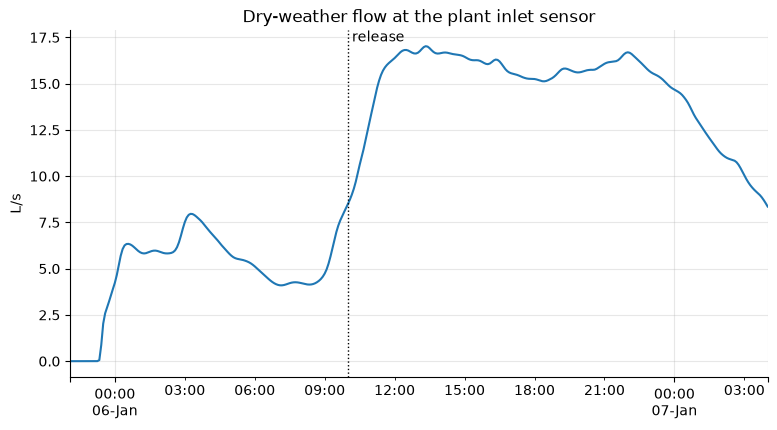

In [5]:
dq = pd.Series(res["q"][i] * 1000, index=res["times"])
ax = dq.plot(title="Dry-weather flow at the plant inlet sensor", ylabel="L/s")
ax.axvline(release, color="k", ls=":", lw=1); ax.text(release, ax.get_ylim()[1], " release", va="top");

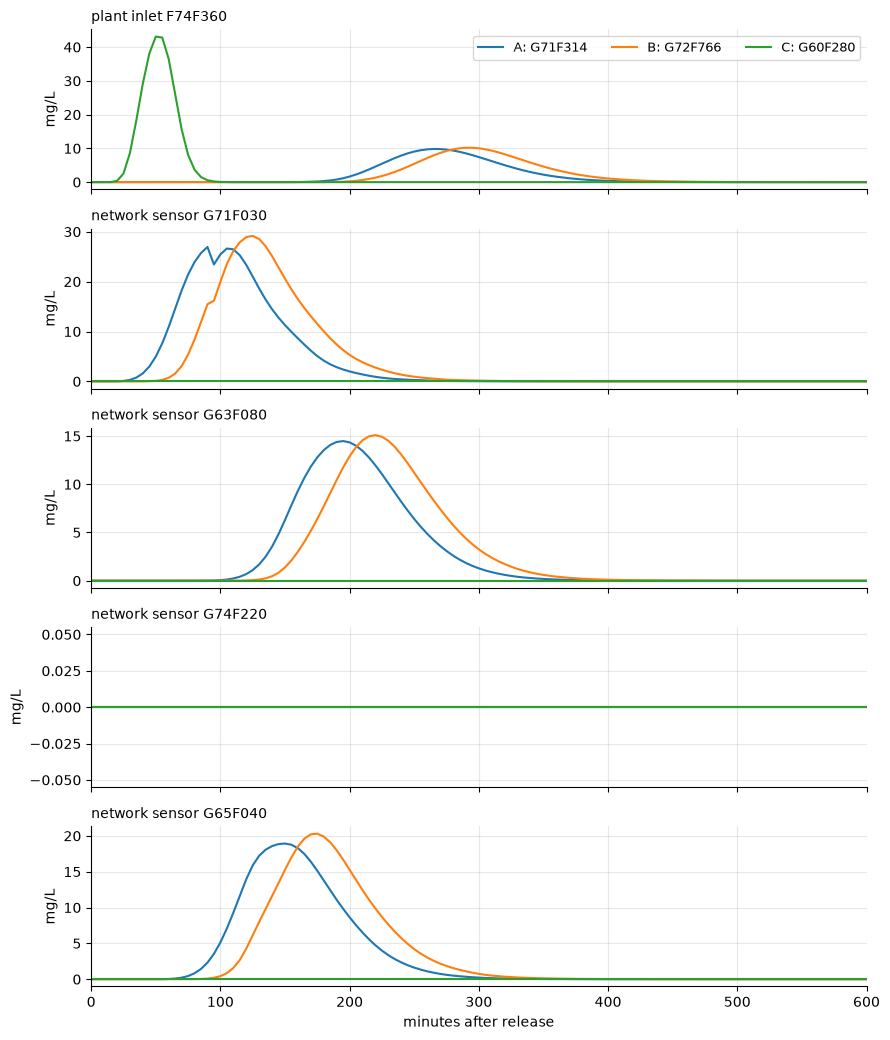

In [6]:
fig, axes = plt.subplots(len(SENSORS), 1, figsize=(9, 2.1 * len(SENSORS)), sharex=True)
mins = (res["times"] - release).total_seconds() / 60
for ax, j, s in zip(axes, range(len(SENSORS)), SENSORS):
    for k, (tracer, node) in enumerate(SOURCES.items()):
        ax.plot(mins, res["c"][k, j], label=f"{tracer}: {node}")
    ax.set_ylabel("mg/L"); ax.set_title(("plant inlet " if s == OUTLET else "network sensor ") + s, fontsize=10, loc="left")
axes[0].legend(ncol=3, fontsize=9)
axes[-1].set(xlabel="minutes after release", xlim=(0, 600))
plt.tight_layout()

## Step 4 · What the sensors can and cannot tell apart

Tracer **C** comes from another branch: it reaches the inlet within an hour and passes none of the network
sensors. Any network sensor rules it out at once.

Tracers **A** and **B** are a different story. Both manholes lie on the same sewer line, so their tracer passes
the **same** sensors, with the same shape, about half an hour apart. If you do not know *when* the spill
happened (and you usually do not), a release at A a little later looks almost exactly like a release at B,
at the inlet and at every sensor downstream of both.

In [7]:
rows = []
for j, s in enumerate(SENSORS):
    row = {"sensor": s + (" (inlet)" if s == OUTLET else "")}
    for k, (tracer, node) in enumerate(SOURCES.items()):
        c = res["c"][k, j]
        row[f"{tracer}: {node}"] = f"peak {c.max():.1f} mg/L after {mins[c.argmax()]:.0f} min" if c.max() > 0.01 else "not seen"
    rows.append(row)
pd.DataFrame(rows).style.hide(axis="index")

sensor,A: G71F314,B: G72F766,C: G60F280
F74F360 (inlet),peak 9.8 mg/L after 265 min,peak 10.2 mg/L after 295 min,peak 43.1 mg/L after 50 min
G71F030,peak 26.9 mg/L after 90 min,peak 29.2 mg/L after 125 min,not seen
G63F080,peak 14.5 mg/L after 195 min,peak 15.1 mg/L after 220 min,not seen
G74F220,not seen,not seen,not seen
G65F040,peak 18.9 mg/L after 150 min,peak 20.3 mg/L after 175 min,not seen


This is the main finding of the case: **manholes on the same sewer line look alike at any sensor downstream of
both when the release time is unknown.** Telling them apart takes a sensor *between* them, or knowing the
release time. Sensors spread over **different branches** therefore add far more than sensors stacked on one
line, which is why the choice of sensor sites matters as much as the method that reads them.

## Step 5 · KAI's blind test on the same network

KAI's engine was tested the way it would be used: **53 hidden releases** at 34 candidate manholes, with release
times and durations (30, 60 or 90 minutes) unknown to the engine, 10 % sensor noise, and each manhole's
dry-weather inflow in the "truth" runs scaled at random (standard deviation 25 %) so that the model that searches
is not the model that made the data. For each release, the engine had to name the manhole from the sensor
readings alone. Quality sensors are assumed at the sites listed; the utility's real sites are level and flow
meters today.

**What was left out, and why.** 120 releases were generated. Six candidate manholes at the tops of almost-dry
pipes, where SWMM's water-quality routing loses tracer at night, were removed with their releases, leaving 105:
52 to calibrate the engine's confidence and 53 for the blind test. SWMM's report shows quality-routing continuity
errors of 35 % and 14 % in two of the four batches of truth runs (the library runs balance within 1.3 %); the
report does not separate releases, and the loss most likely comes from the excluded almost-dry pipes. We list it
here rather than hide it; the next engine release reruns the truth batches release by release.

The method itself (a probabilistic source search with calibrated confidence, and greedy sensor placement) is
part of KAI's engine and is not published here; the results are below, from `results/kai_engine_results.json`,
the same file behind the [interactive page](https://hydro-saas.charkaks0.workers.dev/demo/reference/bellinge).

sensor set-up,right manhole first time,right manhole in the top 3,within 500 m,releases
"Inlet sensor, one composite sample every 2 hours",11.3%,32.1%,17.0%,53
"Inlet probe, online",20.8%,43.4%,22.6%,53
Inlet + the utility's 5 existing sites,39.6%,77.4%,47.2%,53
Inlet + 4 sites chosen by the engine,58.5%,73.6%,62.3%,53
"Same 5 sensors, model flows match the network (upper bound of a flow-calibrated model)",60.4%,79.2%,75.5%,53


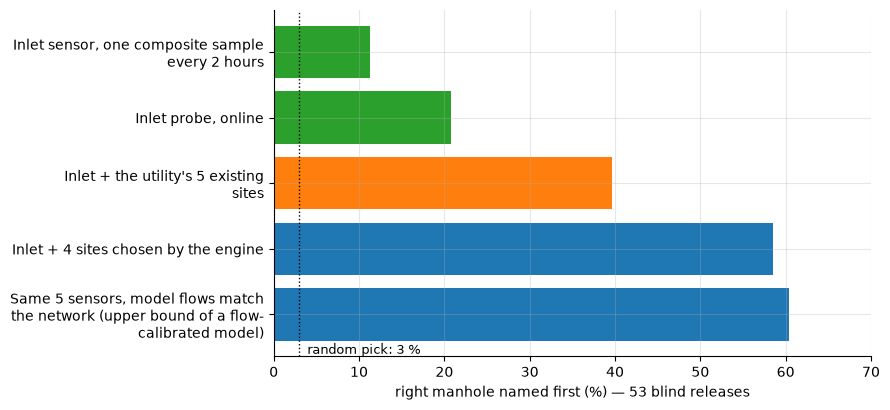

In [8]:
kai = json.loads(Path("results/kai_engine_results.json").read_text())
a = kai["analysis"]
rows = [
    ("Inlet sensor, one composite sample every 2 hours", a["scenarios"]["inlet_composite_2h"]),
    ("Inlet probe, online", a["scenarios"]["inlet_online"]),
    ("Inlet + the utility's 5 existing sites", a["scenarios"]["inlet_plus_utility_sites"]),
    ("Inlet + 4 sites chosen by the engine", a["placement"][-1]["test"]),
    ("Same 5 sensors, model flows match the network (upper bound of a flow-calibrated model)", a["calibrated"]["chosen_sites"]),
]
tab = pd.DataFrame([{"sensor set-up": n, "right manhole first time": r["top1"], "right manhole in the top 3": r["top3"],
                     "within 500 m": r["nearby"], "releases": r["events"]} for n, r in rows])
display(tab.style.format({"right manhole first time": "{:.1%}", "right manhole in the top 3": "{:.1%}", "within 500 m": "{:.1%}"}).hide(axis="index"))

import textwrap
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh([textwrap.fill(x, 36) for x in tab["sensor set-up"][::-1]], tab["right manhole first time"][::-1] * 100, color=["tab:green", "tab:green", "tab:orange", "tab:blue", "tab:blue"][::-1])
ax.axvline(100 / 34, color="k", ls=":", lw=1)
ax.text(100 / 34 + 1, -0.6, "random pick: 3 %", fontsize=9)
ax.set(xlabel="right manhole named first (%) — 53 blind releases", xlim=(0, 70))
plt.tight_layout()

True source G71F314, 1.35 kg; estimated 1.24 kg at the right time.


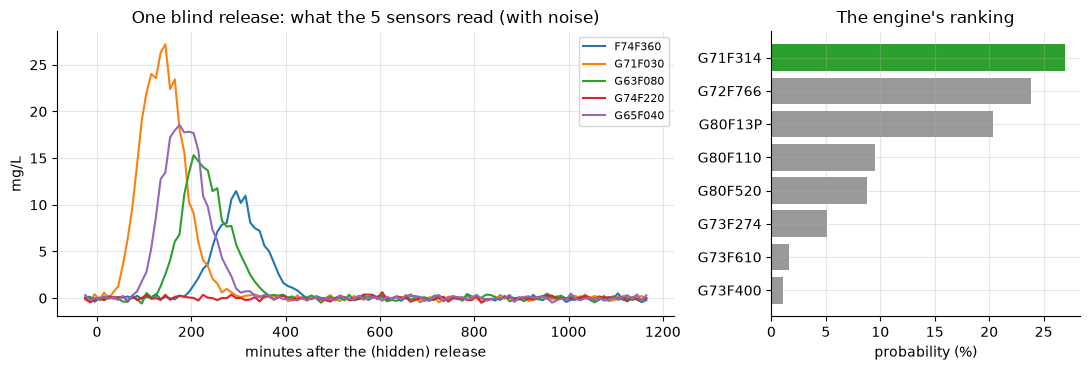

In [9]:
ex = kai["example"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
m = np.array(ex["minutes"]) - ex["true_release_minute"]
for s in ex["sensors"]:
    axes[0].plot(m, ex["observed"][s], label=s)
axes[0].set(title="One blind release: what the 5 sensors read (with noise)", xlabel="minutes after the (hidden) release", ylabel="mg/L")
axes[0].legend(fontsize=8)
top = pd.DataFrame(ex["top"])
axes[1].barh(top["source"][::-1], top["p"][::-1] * 100, color=["tab:green" if s == ex["true_source"] else "0.6" for s in top["source"][::-1]])
axes[1].set(title="The engine's ranking", xlabel="probability (%)")
plt.tight_layout()
print(f"True source {ex['true_source']}, {ex['true_kg']} kg; estimated {ex['estimated_kg']} kg at the right time.")

In this example the true manhole is ranked first, but only just ahead of **G72F766**: the same pair you saw
look alike at the inlet in Step 4. The engine reports that uncertainty instead of hiding it.

**What this means for an industrial park:** an inlet probe alone narrows a spill to a part of the network;
four extra sensors in the right places name the right manhole first time in about 6 releases out of 10. When the
model's flows match the network, the hit rate barely changes but the miss gets closer: within 500 m in 3 out of
4 releases instead of 6 out of 10. The design of the sensor network is part of the service.

---

**On the KAI platform**

* [Bellinge case, interactive](https://hydro-saas.charkaks0.workers.dev/demo/reference/bellinge): the network map, the sensors and the blind-test results.
* [HydroSaaS pollutant loads in a demo park](https://hydro-saas.charkaks0.workers.dev/demo/park/loads): spike-source ranking in an operating park.
* [Water security for industrial parks](https://kai-water.charkaks0.workers.dev/solution-effluent-compliance.html) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free) · [Ask about a sensor design for your park](https://kai-water.charkaks0.workers.dev/contact.html)

*Code: MIT. Text and figures: CC BY 4.0, KAI Water & Energy. Network model: the Bellinge data set (Nedergaard Pedersen et al., 2021), CC BY 4.0, via eWaterCycle (BSD-2-Clause).*